<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/05_audio/02_speech_recognition_whisper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎙️ Application · Speech recognition with Whisper: how well does it hear Africa?

In the previous quest you recognised **10 words** spoken by 6 people. Now: **any sentence**, in **dozens of
languages**, by anyone. That's *automatic speech recognition* (ASR).

**From Audrey to Whisper.**
- **1952** · Bell Labs' *Audrey*: 10 digits, one speaker.
- **1970s-2000s** · *Hidden Markov Models* + MFCCs + huge pronunciation dictionaries; dictation software (Dragon,
  1997) needs you to train it on your own voice.
- **2012** · deep neural networks cut error rates dramatically; voice assistants follow (Siri 2011, Alexa 2014).
- **2022** · OpenAI's **Whisper**: a transformer trained on **680 000 hours** of audio collected from the web, in
  ~100 languages. It transcribes, translates to English, and is open source.

But "~100 languages" hides a huge imbalance: about **438 000 hours of English** in Whisper's training data, and only
a few hours (or minutes) for many African languages. In this notebook we **measure** what that means, using
**FLEURS** (Google, 2022): the same sentences read aloud in 102 languages, perfect for a fair comparison.

| Step | Concept |
|---|---|
| 1. Whisper in 3 lines | encoder-decoder transformer, `pipeline` |
| 2. The metric | **WER** (word error rate), implemented from scratch |
| 3. A fair benchmark | FLEURS in English, French, Swahili, Lingala |
| 4. Model size | whisper-tiny vs whisper-base |
| 5. Zero-shot digits | Whisper vs your trained CNN |
| 6. Translation & next steps | speech → English text, fine-tuning |

⏱️ ~5 minutes. Downloads: two models (150 MB + 290 MB) and ~40 short audio clips.

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "librosa"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import soundfile as sf
import librosa
from IPython.display import Audio, display

quest("How well does Whisper hear Africa?", chapter="Track 5 · Audio · Speech recognition", xp=250)
DEVICE = get_device()

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · How well does Whisper hear Africa?
   Track 5 · Audio · Speech recognition
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


⚙️  Using device: mps  (Apple Silicon GPU (Metal))


## 1. Whisper in three lines 🪄

Whisper is an **encoder-decoder** transformer:
- the **encoder** reads 30 seconds of log-mel spectrogram (exactly what you computed in the quest!),
- the **decoder** writes the transcription token by token, like the tiny GPT of the NLP track, but *conditioned* on
  the audio. Special tokens tell it the language and the task (`<|sw|><|transcribe|>`).

In [3]:
import logging
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
import transformers
transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
from transformers import pipeline

asr = {name: pipeline("automatic-speech-recognition", model=f"openai/whisper-{name}", device=DEVICE)
       for name in ["tiny", "base"]}
for name, p in asr.items():
    print(f"whisper-{name}: {sum(t.numel() for t in p.model.parameters()) / 1e6:.0f}M parameters")

whisper-tiny: 38M parameters
whisper-base: 73M parameters


## 2. Get a fair benchmark: FLEURS samples 🌍

FLEURS is large (gigabytes per language), so we only fetch **10 clips per language** through the Hugging Face
*dataset viewer* API, and cache them in `data/fleurs_samples/`. Our panel: English and French (lots of training
data), **Swahili** (East Africa, ~100 M speakers) and **Lingala** (Central Africa, ~40 M speakers).

In [4]:
LANGS = {"en_us": "english", "fr_fr": "french", "sw_ke": "swahili", "ln_cd": "lingala"}
N_CLIPS = 10
folder = DATA_DIR / "fleurs_samples"
folder.mkdir(exist_ok=True)

def fetch_fleurs(config, n=N_CLIPS):
    index = folder / f"{config}.csv"
    if index.exists():
        return pd.read_csv(index)
    rows = None
    for attempt in range(6):                  # the API sometimes answers "busy" (5xx) on a cold cache: retry
        for split in ["validation", "test"]:  # very large files are refused: try the other split
            url = f"https://datasets-server.huggingface.co/rows?dataset=google/fleurs&config={config}&split={split}&offset=0&length={n}"
            try:
                answer = requests.get(url, timeout=60).json()
            except (requests.RequestException, ValueError):
                answer = {}
            if "rows" in answer:
                rows = answer["rows"]
                break
        if rows is not None:
            break
        time.sleep(10)
    if rows is None:
        print(f"⚠️ {config}: not available through the viewer API right now, skipped")
        return pd.DataFrame(columns=["lang", "path", "text"])
    records = []
    for r in rows:
        row = r["row"]
        path = folder / f"{config}_{row['id']}.wav"
        download(row["audio"][0]["src"], path)
        records.append({"lang": config, "path": str(path.relative_to(DATA_DIR)), "text": row["transcription"]})
    df = pd.DataFrame(records)
    df.to_csv(index, index=False)
    return df

clips = pd.concat([fetch_fleurs(c) for c in LANGS], ignore_index=True)
clips["path"] = clips["path"].map(lambda p: DATA_DIR / p)
print(clips.groupby("lang").size())
row = clips.query("lang == 'sw_ke'").iloc[0]
audio, sr = sf.read(row["path"])
print(f"{sr} Hz, {len(audio) / sr:.1f} s →", row["text"])
display(Audio(audio[: 8 * sr], rate=sr))          # first 8 seconds (keeps the notebook light)

lang
en_us    10
fr_fr    10
ln_cd    10
sw_ke    10
dtype: int64
16000 Hz, 21.4 s → kwa kushirikiana na npws na sporting shooters association of australia nsw inc wajitoleaji waliohitimu waliandikishwa chini ya mpango wa uwindaji wa sporting shooters association


## 3. The metric: Word Error Rate (WER) 📏

WER counts the minimum number of word **s**ubstitutions, **d**eletions and **i**nsertions needed to turn the
prediction into the reference, divided by the number of reference words:

$$\text{WER} = \frac{S + D + I}{N}$$

It's the **edit distance** (Levenshtein, 1965) on words. 0% = perfect; it can exceed 100% if the model invents a lot.
Before comparing, we **normalise** both texts (lowercase, no punctuation), otherwise "Hello," ≠ "hello".

In [5]:
def normalise(t):
    t = t.lower().replace("’", "'")
    t = re.sub(r"[^\w\s']", " ", t)
    return " ".join(t.split())

def edit_distance(ref, hyp):
    d = np.arange(len(hyp) + 1)
    for i, r in enumerate(ref, 1):
        prev, d[0] = d[0], i
        for j, h in enumerate(hyp, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (r != h))
    return d[-1]

def wer(refs, hyps):
    errors = sum(edit_distance(normalise(r).split(), normalise(h).split()) for r, h in zip(refs, hyps))
    return errors / sum(len(normalise(r).split()) for r in refs)

def cer(refs, hyps):   # same on characters: kinder to agglutinative languages and spelling variants
    errors = sum(edit_distance(list(normalise(r)), list(normalise(h))) for r, h in zip(refs, hyps))
    return errors / sum(len(normalise(r)) for r in refs)

print(f"{wer(['the cat sat on the mat'], ['the cat sit on mat']):.0%}  (1 substitution + 1 deletion over 6 words)")

33%  (1 substitution + 1 deletion over 6 words)


## 4. Benchmark: 2 models × 4 languages 🏁

We tell Whisper which language to expect (it can also detect it, but then a detection error would add up).

In [6]:
def transcribe(model_name, paths, language):
    out = []
    for p in paths:
        a, sr = sf.read(p)
        res = asr[model_name]({"raw": a.astype(np.float32), "sampling_rate": sr},
                              generate_kwargs={"language": language, "task": "transcribe", "max_new_tokens": 160})
        out.append(res["text"].strip())
    return out

results, examples = [], {}
for lang, language in LANGS.items():
    sub = clips.query("lang == @lang")
    for model_name in asr:
        hyps = transcribe(model_name, sub["path"], language)
        examples[(lang, model_name)] = (sub["text"].iloc[0], hyps[0])
        results.append({"language": language, "model": f"whisper-{model_name}",
                        "WER": wer(sub["text"], hyps), "CER": cer(sub["text"], hyps)})
res = pd.DataFrame(results)
res.pivot(index="language", columns="model", values="WER").loc[list(LANGS.values())].style.format("{:.0%}").background_gradient(cmap="Reds", vmin=0, vmax=1)

model,whisper-base,whisper-tiny
language,,
english,11%,17%
french,22%,42%
swahili,167%,253%
lingala,94%,132%


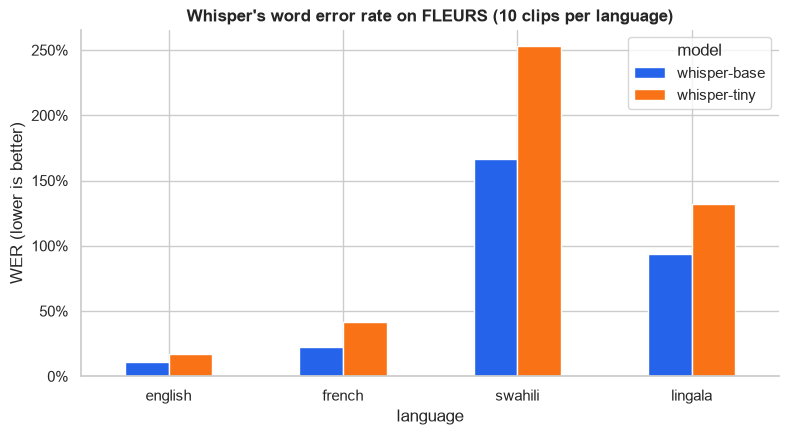

[english]
   reference : when you call someone who is thousands of miles away you are using a satellite
   whisper   : When you call someone who is thousands of miles away, you are using a satellite.

[french]
   reference : il y a de nombreuses répercussions sociales et politiques telles que l'utilisation du système métrique le passage de l'absolutisme au républicanisme le nationalisme et la conviction que le pays appartient au peuple et non à un seul dirigeant
   whisper   : Il y a de nombreuses répercussions sociales et politiques, dès que l'utilisation du système métrique, le passage de l'absolutisme aux républicanismes, une nationalisme et la conviction que le pays appartient au peuple et non à un seul d'ingents.

[swahili]
   reference : kwa kushirikiana na npws na sporting shooters association of australia nsw inc wajitoleaji waliohitimu waliandikishwa chini ya mpango wa uwindaji wa sporting shooters association
   whisper   : Kapusirikiana na NPWS na spotingshotas asoziation of

In [7]:
ax = res.pivot(index="language", columns="model", values="WER").loc[list(LANGS.values())].plot.bar(rot=0)
ax.set(ylabel="WER (lower is better)", title="Whisper's word error rate on FLEURS (10 clips per language)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); plt.show()

short = lambda t, n=260: t if len(t) <= n else t[:n] + " […]"
for (lang, model_name), (ref, hyp) in examples.items():
    if model_name == "base":
        print(f"[{LANGS[lang]}]\n   reference : {short(ref)}\n   whisper   : {short(hyp)}\n")

In [8]:
checkpoint("whisper/benchmark", xp=80)

✅ Checkpoint · whisper/benchmark (+80 XP)
   ███████████████████░░░░░ 80/100 XP


**What the numbers say.**
- **English and French**: whisper-base gets most words right (≈ 1 error every 5-10 words), and it is clearly better
  than whisper-tiny. Size matters.
- **Swahili**: look at the example. The model starts reasonably, then gets stuck repeating the same word over and
  over: a **hallucination loop**, a well-known failure of Whisper on languages it masters poorly. Every repeated
  word is an *insertion*, which is how the WER can climb **far above 100%**.
- **Lingala**: almost every word is wrong… yet read the output aloud: *"Bitu kamingi batu"* for *"bituka mingi
  bato"*. Whisper hears the **sounds** but doesn't know the **words** and their spelling. The CER (character error
  rate) is much lower than the WER for that reason:

In [9]:
res.pivot(index="language", columns="model", values="CER").loc[list(LANGS.values())].round(2)

model,whisper-base,whisper-tiny
language,,
english,0.04,0.06
french,0.10,0.18
swahili,0.79,0.94
lingala,0.27,0.52


That is the **data gap**: the quality of an AI system in a language tracks the amount of training data in that
language.

⚠️ 10 clips per language is a tiny sample: good enough to see big gaps, not to rank close systems. Raise `N_CLIPS`
for a serious evaluation.

## 5. Zero-shot digits: Whisper vs your CNN 🔢

In the quest, your CNN was **trained** on 4 speakers. Whisper was never trained on this dataset (*zero-shot*).
Who wins on the two unseen speakers? (We test 100 clips: Whisper is slower.)

In [10]:
root = download_and_extract("https://codeload.github.com/Jakobovski/free-spoken-digit-dataset/zip/refs/heads/master",
                            "fsdd", marker="free-spoken-digit-dataset-master")
digit_files = sorted((root / "free-spoken-digit-dataset-master" / "recordings").glob("*.wav"))
digit_files = [p for p in digit_files if p.stem.split("_")[1] in ("theo", "yweweler")]
rng = np.random.default_rng(SEED)
digit_files = [digit_files[i] for i in rng.choice(len(digit_files), 100, replace=False)]

WORDS = {"zero": 0, "oh": 0, "one": 1, "two": 2, "to": 2, "too": 2, "three": 3, "four": 4, "for": 4,
         "five": 5, "six": 6, "seven": 7, "eight": 8, "nine": 9}

def to_digit(text):
    t = normalise(text)
    if t[:1].isdigit():
        return int(t[0])
    return next((WORDS[w] for w in t.split() if w in WORDS), -1)

hits = []
for p in digit_files:
    a, sr = librosa.load(p, sr=16000)                         # Whisper expects 16 kHz audio
    text = asr["base"]({"raw": a, "sampling_rate": 16000}, generate_kwargs={"language": "english"})["text"]
    hits.append(to_digit(text) == int(p.stem.split("_")[0]))
print(f"Whisper-base zero-shot accuracy on unseen speakers' digits: {np.mean(hits):.0%}")

Whisper-base zero-shot accuracy on unseen speakers' digits: 62%


A model that was never shown this dataset gets a majority of the digits right, despite the 8 kHz telephone-quality
audio (it was trained on 16 kHz web audio) and single words without any context. That's the power of **large-scale
pre-training**. But your small CNN from the quest, trained in a few seconds on 4 speakers, did **better** on this
narrow task (~76%): a specialised small model is often the pragmatic choice in production (faster, cheaper, works
offline).

## 6. Bonus: speech translation 🔁

Whisper can also **translate** speech from any of its languages directly into English text.

In [11]:
for lang in ["fr_fr", "sw_ke"]:
    r = clips.query("lang == @lang").iloc[1]
    a, sr = sf.read(r["path"])
    en = asr["base"]({"raw": a.astype(np.float32), "sampling_rate": sr},
                     generate_kwargs={"language": LANGS[lang], "task": "translate", "max_new_tokens": 160})["text"]
    print(f"[{LANGS[lang]}] {r['text']}\n   → English: {short(en.strip())}\n")

[french] il n'avait pas non plus le pouvoir de déroger aux lois fiscales ni à celles sur les droits de douane entre les états
   → English: There was not much power to say about the Fiskal magic, there are only 3 of them between the stars.



[swahili] amazon pia ni mto mpana zaidi duniani wakati mwingine maili sita kwa upana
   → English: I'm going to go to bed early in the morning. I'm going to go to bed early in the morning. I'm going to bed early in the morning. I'm going to bed early in the morning. I'm going to bed early in the morning. I'm going to bed early in the morning. I'm going to b […]



With a 73M-parameter model, translation is rough: the French one keeps part of the meaning, the Swahili one is
invented (and loops again). Translation quality collapses where transcription already struggles; the large
Whisper models do much better.

## 7. How do we close the gap? 🛠️

1. **Bigger models**: `whisper-small`, `-medium`, `-large-v3` are much better on low-resource languages (but heavier).
2. **Fine-tuning** on transcribed speech in the target language: a few hours of data can cut the WER dramatically.
   The recipe: `WhisperProcessor` + `Seq2SeqTrainer` (see the Hugging Face guide *"Fine-Tune Whisper For Multilingual
   ASR"*).
3. **Collect data**: community projects record and transcribe African languages (Mozilla Common Voice, FLEURS,
   AfriSpeech-200 for accented English, Lacuna Fund and Masakhane projects), and several Zindi challenges target ASR
   for African languages. Contributing a few sentences of your language to Common Voice is a real contribution
   to the field.

## 🏆 Quest complete!

### 🚀 Your turn (bonus XP)
1. Add more languages to `LANGS`: `"am_et"` (amharic), `"yo_ng"` (yoruba), `"ha_ng"` (hausa), `"zu_za"` (zulu)…
   Some files are too large for the viewer API: then download one FLEURS Parquet shard from the Hub (~200-800 MB).
2. Remove the `language` argument and let Whisper detect it. How often is it wrong for Swahili or Lingala?
3. Try `openai/whisper-small` on Swahili (1 GB download). How much does the WER drop?
4. Record a voice note in your language and transcribe it.

In [12]:
checkpoint("whisper/complete", xp=170)
badge("Polyglot Ears", "🎙️")
progress()

✅ Checkpoint · whisper/complete (+170 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ██████████████████░░░░░░ 250/300 XP
╔═══════════════════════════════════╗
║ 🎙️  BADGE UNLOCKED: Polyglot Ears ║
╚═══════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 2
Badges: 🎙️ Polyglot Ears
